# 🐧 ASSIGNMENT — The Penguin Field Guide (EDA)

| | |
|---|---|
| **Student Name** | _____________________________ |
| **Student ID** | _____________________________ |
| **Due Date** | _____________________________ |
| **Total Marks** | **100** (+10 bonus) |

---
### 🎬 The scenario
> *You're a **field biologist** at the Palmer Research Station in Antarctica. Your team has measured **344 penguins** across three species — **Adélie, Chinstrap, and Gentoo** — recording bill size, flipper length, and body mass.*
>
> *Next season, junior researchers need to identify species **in the field, from measurements alone.** Your assignment: use EDA to discover each species' "measurement fingerprint" and produce a simple **field guide** for telling them apart.*

### 🎯 What you'll be graded on
Not just working code — **correct analysis and clear, evidence-based conclusions.** Every chart should help answer: *what makes each species distinct?*

### 📤 Submission
Run all cells before submitting (Kernel → Restart & Run All). Answer every **✍️ Written Answer** box in your own words. Save and submit this `.ipynb` file with all outputs visible.

### 📋 Mark breakdown
| Part | Task | Marks |
|---|---|---|
| **A** | Setup & load the data | 10 |
| **B** | Clean the data (justify your choices) | 15 |
| **C** | Categorical EDA (species & islands) | 15 |
| **D** | Numerical EDA (distributions & correlations) | 20 |
| **E** | Species fingerprints (the core analysis) | 25 |
| **F** | Written field guide (your conclusions) | 15 |
| **Bonus** | Identify a mystery penguin | +10 |

---

## Part A — Setup & Load  *(10 marks)*

In [ ]:
# TODO (5): import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn theme to 'whitegrid'.
sns.set_theme(style='whitegrid')

In [ ]:
# TODO (5): Load the penguins dataset (offline):  df = sns.load_dataset('penguins')
df = sns.load_dataset('penguins')

# Print its shape, and show the first 5 rows. Then run df.info().
print("Shape:", df.shape)

display(df.head())

df.info()

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


## Part B — Clean the Data  *(15 marks)*
Real field data has gaps. Handle them thoughtfully — and **justify** each choice.

In [ ]:
# TODO (5): Print the number of missing values in each column.
df.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [ ]:
# TODO (10):
print("Shape before cleaning:", df.shape)

# - A few rows are missing ALL measurements → drop those rows.
# - Some rows are missing 'sex' → drop those rows too (we need it later).
# Hint: df = df.dropna().reset_index(drop=True)
df = df.dropna().reset_index(drop=True)

# Print the shape before and after.
print("Shape after cleaning:", df.shape)

Shape before cleaning: (344, 7)
Shape after cleaning: (333, 7)


**✍️ Written Answer B (marks for reasoning):** How many rows did you remove, and what % of the data was that? Was dropping them safe? Why?
*Your answer:* _______________

I removed 11 rows, which is about 3.2% of the original 344 rows. Dropping them was reasonable because only a small proportion of the dataset was affected. The removed rows had missing measurements or missing sex values, which would make them incomplete for later analysis. Since about 96.8% of the data remained, the cleaning step should have only a small effect on the overall results.

## Part C — Categorical EDA  *(15 marks)*
*How many of each species, and where do they live?*

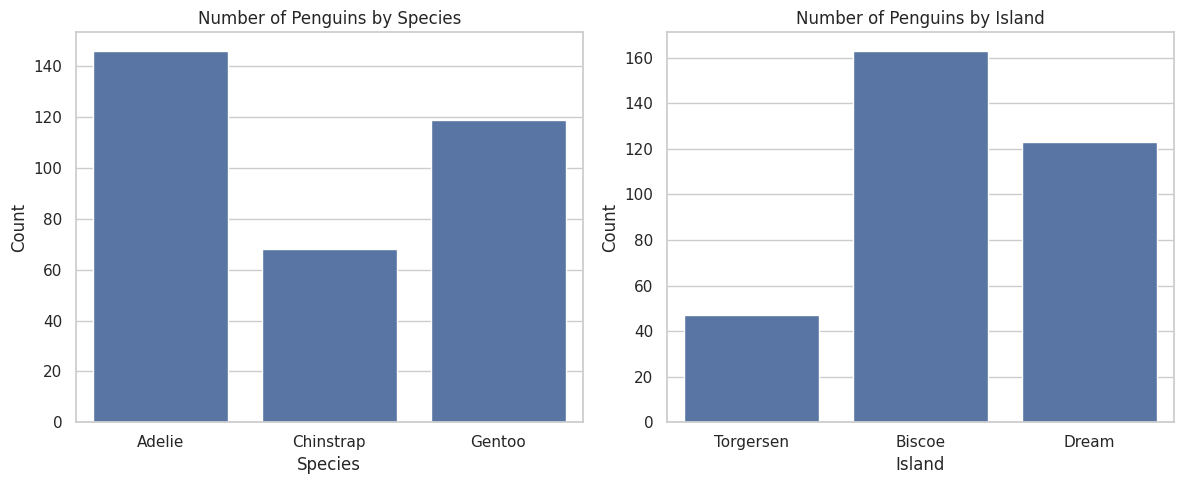

In [ ]:
# TODO (8): In a 1×2 grid, plot a countplot of 'species' and a countplot of 'island'.
# Give each a clear title.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Countplot for species
sns.countplot(data=df, x='species', ax=axes[0])
axes[0].set_title('Number of Penguins by Species')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Count')

# Countplot for island
sns.countplot(data=df, x='island', ax=axes[1])
axes[1].set_title('Number of Penguins by Island')
axes[1].set_xlabel('Island')
axes[1].set_ylabel('Count')

# Improve spacing
plt.tight_layout()
plt.show()

island     Biscoe  Dream  Torgersen
species                            
Adelie         44     55         47
Chinstrap       0     68          0
Gentoo        119      0          0


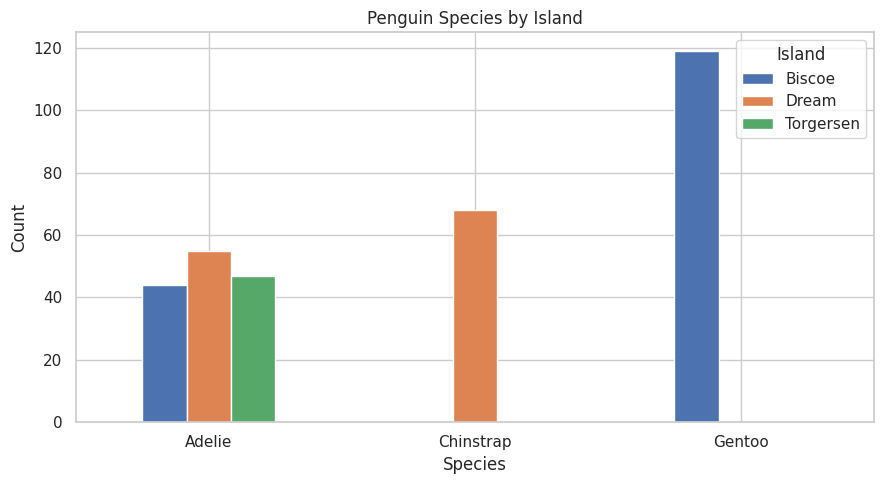

In [ ]:
# TODO (7): Make a crosstab of species vs island (pd.crosstab) and plot it as a bar chart.
# Which islands does each species live on?

species_island = pd.crosstab(df['species'], df['island'])

# Display the table
print(species_island)

# Plot as a bar chart
species_island.plot(kind='bar', figsize=(9, 5))

plt.title('Penguin Species by Island')
plt.xlabel('Species')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Island')
plt.tight_layout()
plt.show()

**✍️ Written Answer C:** Which species is the most common? Is any species found on only ONE island? (That's a huge clue for identification.)
*Your answer:* _______________

Adélie is the most common species in the cleaned dataset. Adélie penguins are found on all three islands: Biscoe, Dream, and Torgersen. Chinstrap penguins are found only on Dream Island, while Gentoo penguins are found only on Biscoe Island. This makes island a very useful clue for identification, especially for Chinstrap and Gentoo.

## Part D — Numerical EDA  *(20 marks)*
*Understand the four body measurements.*

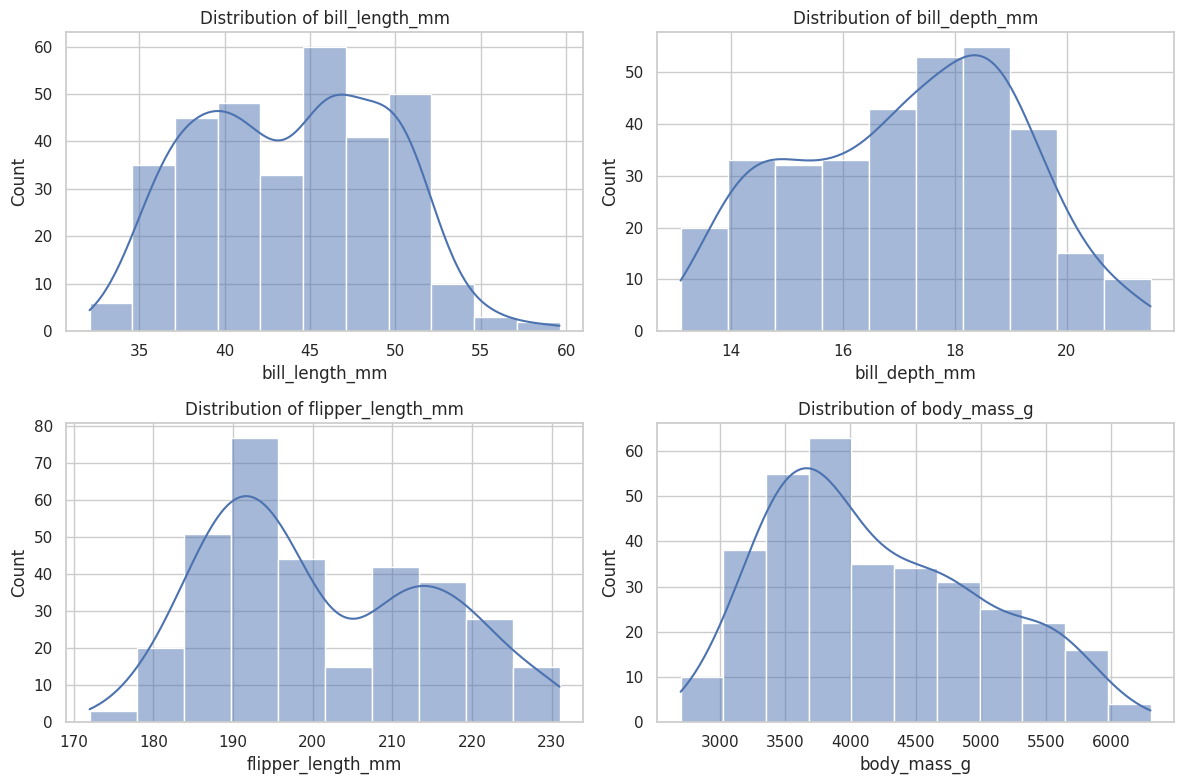

In [ ]:
# TODO (10): For each of the 4 measurements
#   (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g),
measurements = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

# plot a histogram with kde=True. Arrange as a 2×2 grid.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flatten(), measurements):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

# Look: are any distributions clearly split into groups (bumps)? That hints at species!

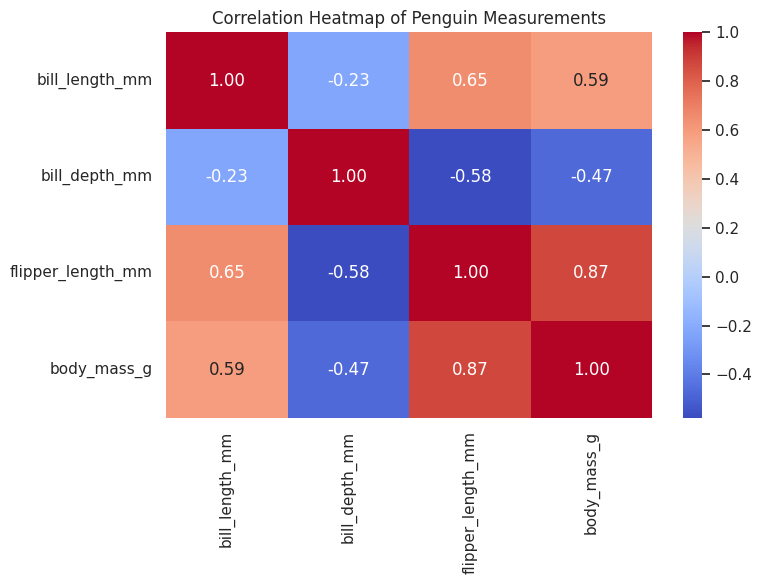

In [ ]:
# TODO (10): Plot a correlation heatmap of the 4 numeric measurements (annot=True).
# Correlation matrix for the 4 numeric measurements
corr_matrix = df[measurements].corr()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Penguin Measurements')
plt.tight_layout()
plt.show()

# Which two measurements are most strongly related?
# Flipper length and body mass have the strongest positive correlation, at about
# 0.87. This makes biological sense because larger penguins generally tend to be
# heavier and have longer flippers. Therefore, as a penguin’s overall body size
# increases, both its body mass and flipper length tend to increase.

**✍️ Written Answer D:** Which two measurements have the strongest positive correlation, and does that make biological sense (think: bigger penguin → ?)
*Your answer:* _______________

Flipper length and body mass have the strongest positive correlation, at about 0.87. This makes biological sense because larger penguins generally have greater body mass and longer flippers. Therefore, as the overall size of a penguin increases, both its weight and flipper length tend to increase.

## Part E — Species Fingerprints  *(25 marks)*  🎯 *the core of the assignment*
*This is where you crack the case: which measurements tell the species apart?*

In [ ]:
# TODO (9): Compute the MEAN of each measurement grouped by species.
#   df.groupby('species')[num_cols].mean()
# This table is the heart of your field guide — study it.

num_cols = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

species_means = df.groupby('species')[num_cols].mean()

species_means

# This table is especially important because it shows each species’ typical measurement
# fingerprint. You should notice that Gentoo penguins are much heavier and have longer
# flippers, while Chinstrap penguins tend to have the longest bills, and Adélie penguins tend to have shorter bills and flippers.

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.823973,18.347260,190.102740,3706.164384
Chinstrap,48.833824,18.420588,195.823529,3733.088235
Gentoo,47.568067,14.996639,217.235294,5092.436975


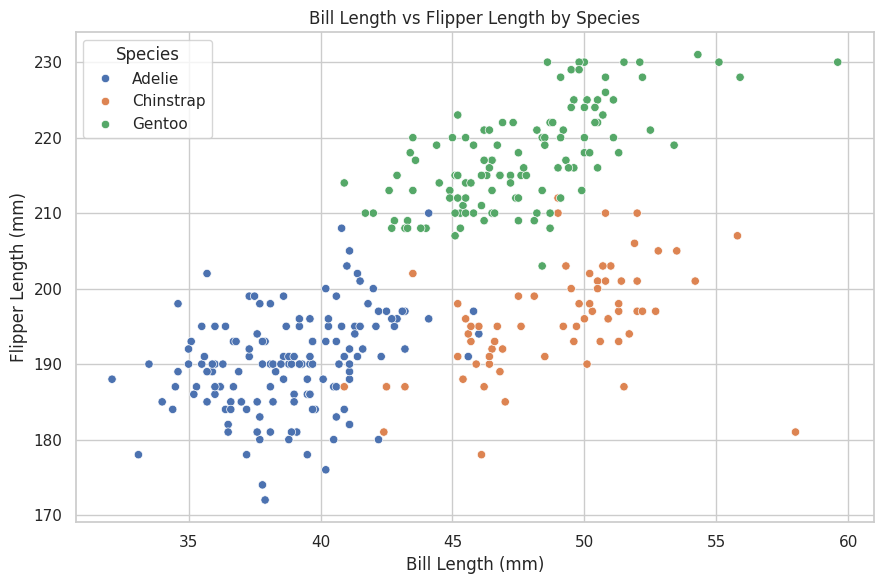

In [ ]:
# TODO (8): Make a scatter plot of bill_length_mm (x) vs flipper_length_mm (y),
# coloured by species (hue='species'). Do the species form separate clusters?

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='species'
)

plt.title('Bill Length vs Flipper Length by Species')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.legend(title='Species')
plt.tight_layout()
plt.show()

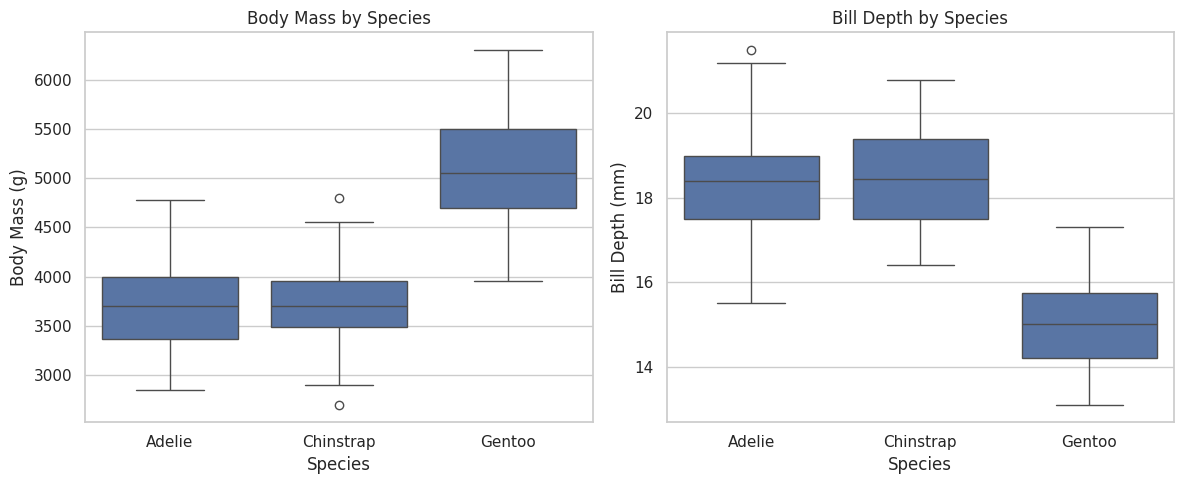

In [ ]:
# TODO (8): Make boxplots of body_mass_g by species, and bill_depth_mm by species
# (1×2 grid). Which species is the clear outlier in size?

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='species', y='body_mass_g', ax=axes[0])
axes[0].set_title('Body Mass by Species')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Body Mass (g)')

sns.boxplot(data=df, x='species', y='bill_depth_mm', ax=axes[1])
axes[1].set_title('Bill Depth by Species')
axes[1].set_xlabel('Species')
axes[1].set_ylabel('Bill Depth (mm)')

plt.tight_layout()
plt.show()

**✍️ Written Answer E:** Describe each species in ONE sentence using measurements. For example: *"Gentoos are the ___ (heaviest/lightest), with the ___ flippers and a ___ bill."* Do this for all three species.
*Adélie:* _______________
*Chinstrap:* _______________
*Gentoo:* _______________

Adélie: Adélies are the lightest penguins, with the shortest flippers and the shortest bills.

Chinstrap: Chinstraps are similar in weight to Adélies, but have longer flippers and the longest, relatively deep bills.

Gentoo: Gentoos are the heaviest penguins, with the longest flippers and much shallower bills.

## Part F — Your Field Guide  *(15 marks)*
Write a short **field guide** (4–6 sentences) that a junior researcher could use to identify a penguin from measurements alone. Base every rule on your charts. A good guide gives simple decision rules, e.g. *"If flipper length > 210mm, it's almost certainly a Gentoo."*

**✍️ Your Field Guide:**

> _______________________________________________
>
> _______________________________________________
>
> _______________________________________________

Start with flipper length: if it is above about 210 mm, the penguin is very likely a Gentoo, especially if its body mass is also high. Gentoos are the largest species overall, with the longest flippers, highest body mass, and relatively shallow bills. If the flipper is shorter, check bill length: Adélies usually have shorter bills, while Chinstraps usually have much longer bills. Chinstraps are generally medium-sized and have deeper bills than Gentoos. In short, large body size and long flippers suggest Gentoo, a short bill suggests Adélie, and a long bill with a smaller body than Gentoo suggests Chinstrap.

## 🌟 Bonus — Identify the Mystery Penguin  *(+10 marks)*
A researcher measured a penguin but forgot to record its species:

> **bill_length = 46 mm, bill_depth = 15 mm, flipper_length = 217 mm, body_mass = 5000 g**

Using your fingerprints from Part E, decide which species it is — and **justify with the data** (which measurements gave it away?).

Species means:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.823973,18.347260,190.102740,3706.164384
Chinstrap,48.833824,18.420588,195.823529,3733.088235
Gentoo,47.568067,14.996639,217.235294,5092.436975


Mystery penguin:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,46,15,217,5000


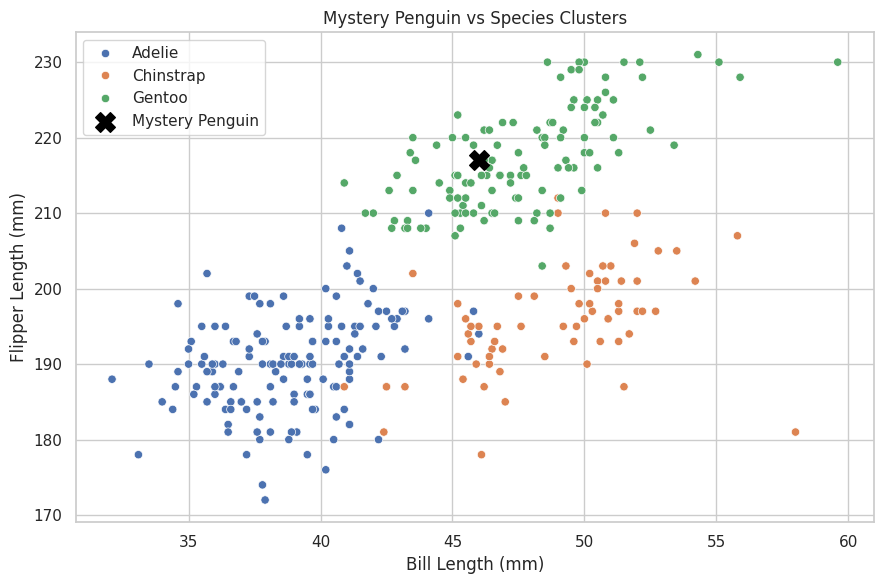

In [ ]:
# TODO (bonus): Justify your answer with code — e.g. compare this penguin's numbers
# to the species means, or plot it on top of your scatter from Part E.

# Mystery penguin measurements
mystery = {
    'bill_length_mm': 46,
    'bill_depth_mm': 15,
    'flipper_length_mm': 217,
    'body_mass_g': 5000
}

# Compare mystery penguin with species means
print("Species means:")
display(species_means)

print("Mystery penguin:")
display(pd.DataFrame([mystery]))

# Plot mystery penguin on the bill length vs flipper length scatterplot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='species'
)

# Add mystery penguin
plt.scatter(
    mystery['bill_length_mm'],
    mystery['flipper_length_mm'],
    marker='X',
    s=200,
    color='black',
    label='Mystery Penguin'
)

plt.title('Mystery Penguin vs Species Clusters')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.legend()
plt.tight_layout()
plt.show()

**✍️ Bonus Answer:** This penguin is a **_______**, because _______________

This penguin is a Gentoo, because its 217 mm flipper length, 5000 g body mass, and shallow 15 mm bill depth closely match the Gentoo measurement fingerprint.

---
### ✅ Before you submit
- [ ] Every `# TODO` cell has working code
- [ ] Every ✍️ Written Answer is filled in
- [ ] You ran **Kernel → Restart & Run All** with no errors
- [ ] Charts have titles and are readable

*Good luck, field biologist!* 🐧